# CS2229 - Tái lập Sharpness-Aware Minimization trên CIFAR-10

Notebook này là pipeline dùng chung của nhóm để so sánh **SGD** và **SAM-SGD** trong cùng điều kiện.

Mục tiêu chính:

- Dùng cùng data split, augmentation, model và training recipe cho hai phương pháp.
- Chọn checkpoint tốt nhất chỉ bằng validation accuracy.
- Lưu đầy đủ config, lịch sử huấn luyện, checkpoint, biểu đồ và thông tin môi trường.
- Có chế độ smoke test 5 epochs để kiểm tra pipeline trước khi chạy đủ 200 epochs.

> Notebook đang được cấu hình để **Run all** sẽ yêu cầu quyền Google Drive, sau đó tự chạy smoke test 5 epochs cho SGD và SAM. Nếu mount Drive thất bại, notebook dừng trước khi train.

Tham chiếu: Foret et al., *Sharpness-Aware Minimization for Efficiently Improving Generalization*, ICLR 2021.
> Lưu ý về provenance: các output đang lưu trong file được tạo bởi `sam_reproduction_vi_v3`, trước khi cơ chế resume được bổ sung. Hãy chạy lại các cell khi cần artifact mang phiên bản v4.


## 1. Kiểm tra môi trường

Google Colab đã có sẵn PyTorch, torchvision, NumPy, pandas và matplotlib. Cell dưới đây chỉ import package, in phiên bản và chọn GPU nếu khả dụng.

Khuyến nghị trên Colab: **Runtime -> Change runtime type -> T4 GPU**. Notebook vẫn chạy được bằng CPU ở chế độ smoke test nhưng sẽ chậm hơn.

In [1]:
# Import toàn bộ dependency dùng trong notebook.
import json
import gc
import platform
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from IPython.display import display
from torch.optim import SGD
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import CIFAR10


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"Thiết bị: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Cảnh báo: chưa có GPU. Full run với WRN-28-10 sẽ rất chậm.")

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
Thiết bị: cuda
GPU: Tesla T4


## 2. Cấu hình thực nghiệm

Đây là cell duy nhất mỗi thành viên cần thay đổi.

- `METHOD`: `"sgd"` hoặc `"sam"`.
- `MODEL`: dùng `"wrn28x10"` cho thí nghiệm chính.
- `SEED`: seed được phân công cho thành viên.
- `RUN_ID`: dùng khi gọi một run riêng lẻ; smoke pair tự tạo `smoke_sgd_s<seed>` và `smoke_sam_s<seed>`.
- `RESUME_IF_EXISTS=True`: tự tiếp tục run chưa hoàn tất có cùng cấu hình và `RUN_ID`. Run đã có `summary.json` vẫn bị từ chối để tránh ghi đè.
- `METHOD`: dùng khi gọi một run riêng lẻ; Run all smoke pair luôn chạy cả SGD rồi SAM.
- `SMOKE_TEST=True`: tự dùng WRN-16-1, tập con nhỏ và 5 epochs.
- `SMOKE_TEST=False`: dùng toàn bộ cấu hình chính.

Khi Run all, pipeline yêu cầu quyền Google Drive và lưu kết quả vào `MyDrive/CS2229-SAM/results`. Nếu quyền bị từ chối, mount lỗi hoặc thư mục không ghi được, notebook dừng ngay và không fallback sang `/content`. Pipeline vẫn từ chối ghi đè một thư mục run đã tồn tại.

In [2]:
# =========================
# CẤU HÌNH CẦN THAY ĐỔI
# =========================
METHOD = "sam"                 # Chọn "sgd" hoặc "sam".
DATASET = "cifar10"            # Notebook hiện chỉ hỗ trợ CIFAR-10.
MODEL = "wrn28x10"             # Model chính theo kế hoạch thực nghiệm.
SEED = 0                        # Seed cho initialization và data loader.
RHO = 0.05                      # Bán kính lân cận của SAM.
LABEL_NOISE = 0.0               # 0.0, 0.4 hoặc 0.8 theo run matrix.
EPOCHS = 200                    # Số epoch của full run.
RUN_ID = "smoke_sam_s0"        # Run chưa hoàn tất có thể dùng lại để resume.
RESUME_IF_EXISTS = True          # Tự tiếp tục từ last_checkpoint.pt nếu có.

# Giữ True cho lần chạy đầu tiên trên Colab.
SMOKE_TEST = True

# Hyperparameter dùng chung cho SGD và SAM.
BATCH_SIZE = 128
LEARNING_RATE = 0.1
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
VALIDATION_SIZE = 5_000
SPLIT_SEED = 20261023           # Cố định để mọi method và seed dùng cùng split.

# Dataset cache ở local runtime; artifact bắt buộc lưu trên Google Drive.
DATA_ROOT = Path("/content/data")
USE_GOOGLE_DRIVE = True
GOOGLE_DRIVE_MOUNT_POINT = Path("/content/drive")
GOOGLE_DRIVE_RESULTS_DIR = Path("MyDrive/CS2229-SAM/results")
RESULTS_ROOT = None  # Được gán sau khi mount và kiểm tra quyền ghi thành công.

# Cấu hình nhẹ chỉ dùng để kiểm tra pipeline.
SMOKE_MODEL = "wrn16x1"
SMOKE_EPOCHS = 5
SMOKE_TRAIN_SIZE = 1_024
SMOKE_VALIDATION_SIZE = 256
SMOKE_TEST_SIZE = 256

# Nhãn phiên bản giúp truy ngược notebook đã tạo artifact.
NOTEBOOK_VERSION = "sam_reproduction_vi_v4"


In [3]:
# Kiểm tra sớm các giá trị dễ nhập sai trước khi tải dữ liệu.
METHOD = METHOD.lower()
DATASET = DATASET.lower()
MODEL = MODEL.lower()

if METHOD not in {"sgd", "sam"}:
    raise ValueError("METHOD phải là 'sgd' hoặc 'sam'.")
if DATASET != "cifar10":
    raise ValueError("Notebook hiện chỉ hỗ trợ DATASET='cifar10'.")
if MODEL not in {"wrn28x10", "wrn16x4", "wrn16x1"}:
    raise ValueError("MODEL phải là wrn28x10, wrn16x4 hoặc wrn16x1.")
if not 0.0 <= LABEL_NOISE < 1.0:
    raise ValueError("LABEL_NOISE phải thuộc khoảng [0, 1).")
if METHOD == "sam" and RHO <= 0:
    raise ValueError("RHO phải lớn hơn 0 khi dùng SAM.")
if not RUN_ID.strip():
    raise ValueError("RUN_ID không được để trống.")

EFFECTIVE_MODEL = SMOKE_MODEL if SMOKE_TEST else MODEL
EFFECTIVE_EPOCHS = SMOKE_EPOCHS if SMOKE_TEST else EPOCHS

print("Cấu hình đang dùng:")
print(f"  method={METHOD}, model={EFFECTIVE_MODEL}, seed={SEED}")
print(f"  rho={RHO}, label_noise={LABEL_NOISE}, epochs={EFFECTIVE_EPOCHS}")
print(f"  run_id={RUN_ID}, smoke_test={SMOKE_TEST}")

Cấu hình đang dùng:
  method=sam, model=wrn16x1, seed=0
  rho=0.05, label_noise=0.0, epochs=5
  run_id=smoke_sam_s0, smoke_test=True


### 2.1. Kết nối Google Drive

Cell dưới đây mở hộp thoại cấp quyền của Google Colab. Mỗi thành viên đăng nhập và tự xác nhận quyền cho Drive của mình.

Pipeline dùng cơ chế **fail-closed**:

- chỉ tiếp tục khi hệ điều hành xác nhận `/content/drive` là mount point và `MyDrive` đã tồn tại;
- tạo được thư mục `MyDrive/CS2229-SAM/results`;
- ghi, đọc và xóa được một file kiểm tra nhỏ;
- không chuyển sang lưu tạm trong `/content` khi có lỗi.

Do đó, khi cell này báo lỗi, cần xử lý kết nối Drive trước khi chạy các cell tiếp theo.

In [4]:
def setup_google_drive_results(
    mount_point=Path("/content/drive"),
    results_relative_dir=Path("MyDrive/CS2229-SAM/results"),
    drive_module=None,
    mount_checker=None,
):
    """Mount Drive, kiểm tra mount thật và xác minh quyền ghi artifact."""
    if drive_module is None:
        try:
            from google.colab import drive as drive_module
        except ImportError as error:
            raise RuntimeError(
                "Google Drive chỉ được mount trong Google Colab. "
                "Hãy upload notebook lên Colab rồi chạy lại."
            ) from error
    if mount_checker is None:
        import os

        mount_checker = os.path.ismount

    try:
        drive_module.mount(str(mount_point))
    except Exception as error:
        raise RuntimeError(
            "Không mount được Google Drive. Notebook đã dừng và chưa bắt đầu training."
        ) from error

    # Không tự tạo MyDrive: thư mục này phải do DriveFS cung cấp sau khi mount thật.
    drive_root = mount_point / "MyDrive"
    if not mount_checker(str(mount_point)) or not drive_root.is_dir():
        raise RuntimeError(
            "Google Drive chưa sẵn sàng tại mount point. "
            "Notebook đã dừng và chưa bắt đầu training."
        )

    if (
        results_relative_dir.is_absolute()
        or not results_relative_dir.parts
        or results_relative_dir.parts[0] != "MyDrive"
        or ".." in results_relative_dir.parts
    ):
        raise ValueError("GOOGLE_DRIVE_RESULTS_DIR phải là đường dẫn tương đối bên trong MyDrive.")

    results_directory = mount_point / results_relative_dir
    probe_path = None
    try:
        from uuid import uuid4

        results_directory.mkdir(parents=True, exist_ok=True)
        probe_path = results_directory / f".write_probe_{uuid4().hex}"
        with probe_path.open("x", encoding="utf-8") as probe_file:
            probe_file.write("google-drive-write-ok")
        if probe_path.read_text(encoding="utf-8") != "google-drive-write-ok":
            raise OSError("Nội dung file kiểm tra không khớp.")
        probe_path.unlink()
    except Exception as error:
        try:
            if probe_path is not None and probe_path.exists():
                probe_path.unlink()
        except OSError:
            pass
        raise RuntimeError(
            "Google Drive đã mount nhưng thư mục kết quả không ghi được. "
            "Notebook đã dừng và chưa bắt đầu training."
        ) from error

    return results_directory


if not USE_GOOGLE_DRIVE:
    raise RuntimeError(
        "Notebook này yêu cầu USE_GOOGLE_DRIVE=True để tránh mất artifact khi Colab ngắt phiên."
    )

RESULTS_ROOT = setup_google_drive_results(
    mount_point=GOOGLE_DRIVE_MOUNT_POINT,
    results_relative_dir=GOOGLE_DRIVE_RESULTS_DIR,
)
print(f"Artifact sẽ được lưu tại: {RESULTS_ROOT}")

Mounted at /content/drive
Artifact sẽ được lưu tại: /content/drive/MyDrive/CS2229-SAM/results


## 3. Reproducibility và utility

Cell này cố định các nguồn ngẫu nhiên chính. `SPLIT_SEED` tách khỏi `SEED` để toàn bộ run dùng cùng train/validation split, còn `SEED` điều khiển initialization, thứ tự mini-batch và augmentation.

PyTorch vẫn có thể có sai khác nhỏ giữa GPU hoặc phiên bản CUDA khác nhau. `environment.txt` sẽ ghi lại môi trường để giải thích các sai khác đó.

In [5]:
def seed_everything(seed):
    """Cố định các nguồn ngẫu nhiên thường dùng trong pipeline."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Chế độ deterministic ưu tiên khả năng tái lập hơn tốc độ.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    """Đồng bộ seed của NumPy và random trong từng DataLoader worker."""
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


class AverageMeter:
    """Tính trung bình có trọng số cho loss hoặc accuracy."""

    def __init__(self):
        self.total = 0.0
        self.count = 0

    def update(self, value, count):
        self.total += float(value) * count
        self.count += count

    @property
    def average(self):
        return self.total / max(self.count, 1)


seed_everything(SEED)

## 4. Chuẩn bị CIFAR-10

Training augmentation bám theo thiết lập phổ biến của WideResNet trên CIFAR-10:

- padding 4 pixels, random crop 32 x 32;
- random horizontal flip;
- chuẩn hóa theo thống kê CIFAR-10.

Validation và test chỉ chuẩn hóa, không dùng augmentation. Label noise chỉ được áp dụng lên training subset.

In [6]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD = (0.2470, 0.2435, 0.2616)
CIFAR10_CLASSES = (
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
)


class NoisySubset(Dataset):
    """Subset có thể thay một tỷ lệ nhãn bằng nhãn sai xác định theo seed."""

    def __init__(self, dataset, indices, noise_rate=0.0, noise_seed=0):
        self.dataset = dataset
        self.indices = list(indices)
        self.targets = [int(dataset.targets[index]) for index in self.indices]

        if noise_rate > 0:
            rng = np.random.default_rng(noise_seed)
            noisy_count = int(round(len(self.targets) * noise_rate))
            noisy_positions = rng.choice(len(self.targets), size=noisy_count, replace=False)

            # Cộng offset từ 1 đến 9 để nhãn mới luôn khác nhãn gốc.
            for position in noisy_positions:
                offset = int(rng.integers(1, 10))
                self.targets[position] = (self.targets[position] + offset) % 10

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        image, _ = self.dataset[self.indices[position]]
        return image, self.targets[position]


def make_split_indices(dataset_size, validation_size, split_seed):
    """Tạo train/validation split cố định và dùng lại cho mọi run."""
    generator = torch.Generator().manual_seed(split_seed)
    permutation = torch.randperm(dataset_size, generator=generator).tolist()
    validation_indices = permutation[:validation_size]
    train_indices = permutation[validation_size:]
    return train_indices, validation_indices


def build_dataloaders():
    """Tạo các DataLoader và giữ split giống nhau giữa SGD với SAM."""
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])
    evaluation_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
    ])

    augmented_dataset = CIFAR10(DATA_ROOT, train=True, download=True, transform=train_transform)
    evaluation_dataset = CIFAR10(DATA_ROOT, train=True, download=True, transform=evaluation_transform)
    test_dataset = CIFAR10(DATA_ROOT, train=False, download=True, transform=evaluation_transform)

    train_indices, validation_indices = make_split_indices(
        len(augmented_dataset), VALIDATION_SIZE, SPLIT_SEED
    )

    if SMOKE_TEST:
        train_indices = train_indices[:SMOKE_TRAIN_SIZE]
        validation_indices = validation_indices[:SMOKE_VALIDATION_SIZE]
        test_dataset = Subset(test_dataset, range(SMOKE_TEST_SIZE))

    train_dataset = NoisySubset(
        augmented_dataset,
        train_indices,
        noise_rate=LABEL_NOISE,
        noise_seed=SEED,
    )
    train_evaluation_dataset = Subset(evaluation_dataset, train_indices)
    validation_dataset = Subset(evaluation_dataset, validation_indices)

    loader_generator = torch.Generator().manual_seed(SEED)
    common_loader_options = {
        "batch_size": BATCH_SIZE,
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "worker_init_fn": seed_worker,
        # Tạo lại worker mỗi epoch để RNG có thể phục hồi sau khi runtime restart.
        "persistent_workers": False,
    }

    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=loader_generator,
        **common_loader_options,
    )
    train_evaluation_loader = DataLoader(
        train_evaluation_dataset,
        shuffle=False,
        **common_loader_options,
    )
    validation_loader = DataLoader(
        validation_dataset,
        shuffle=False,
        **common_loader_options,
    )
    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **common_loader_options,
    )

    split_info = {
        "split_seed": SPLIT_SEED,
        "train_size": len(train_dataset),
        "validation_size": len(validation_dataset),
        "test_size": len(test_dataset),
    }
    return train_loader, train_evaluation_loader, validation_loader, test_loader, split_info

## 5. WideResNet cho CIFAR-10

Thí nghiệm chính dùng `wrn28x10`. Hai biến thể nhỏ hơn giúp giảm chi phí:

- `wrn16x4`: fallback nếu tài nguyên GPU không đủ.
- `wrn16x1`: chỉ dùng cho smoke test và kiểm tra demo.

Nếu nhóm đổi model chính sau smoke test, tất cả thành viên phải dùng cùng một model và ghi rõ đây là *reduced reproduction*.

In [7]:
class WideBasicBlock(nn.Module):
    """Residual block dùng trong WideResNet cho ảnh CIFAR."""

    def __init__(self, in_channels, out_channels, stride, dropout_rate):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.dropout_rate = dropout_rate

        self.shortcut = None
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Conv2d(
                in_channels, out_channels, kernel_size=1, stride=stride, bias=False
            )

    def forward(self, inputs):
        outputs = F.relu(self.bn1(inputs), inplace=True)
        shortcut = inputs if self.shortcut is None else self.shortcut(outputs)
        outputs = self.conv1(outputs)
        outputs = F.relu(self.bn2(outputs), inplace=True)
        if self.dropout_rate > 0:
            outputs = F.dropout(outputs, p=self.dropout_rate, training=self.training)
        outputs = self.conv2(outputs)
        return outputs + shortcut


class WideResNet(nn.Module):
    """WideResNet với depth = 6n + 4 dành cho CIFAR-10."""

    def __init__(self, depth=28, widen_factor=10, dropout_rate=0.0, num_classes=10):
        super().__init__()
        if (depth - 4) % 6 != 0:
            raise ValueError("WideResNet yêu cầu depth có dạng 6n + 4.")

        blocks_per_group = (depth - 4) // 6
        channels = [16, 16 * widen_factor, 32 * widen_factor, 64 * widen_factor]

        self.conv1 = nn.Conv2d(3, channels[0], kernel_size=3, padding=1, bias=False)
        self.group1 = self._make_group(
            blocks_per_group, channels[0], channels[1], stride=1, dropout_rate=dropout_rate
        )
        self.group2 = self._make_group(
            blocks_per_group, channels[1], channels[2], stride=2, dropout_rate=dropout_rate
        )
        self.group3 = self._make_group(
            blocks_per_group, channels[2], channels[3], stride=2, dropout_rate=dropout_rate
        )
        self.bn = nn.BatchNorm2d(channels[3])
        self.classifier = nn.Linear(channels[3], num_classes)
        self._initialize_weights()

    @staticmethod
    def _make_group(block_count, in_channels, out_channels, stride, dropout_rate):
        blocks = []
        for block_index in range(block_count):
            block_stride = stride if block_index == 0 else 1
            block_in_channels = in_channels if block_index == 0 else out_channels
            blocks.append(
                WideBasicBlock(
                    block_in_channels, out_channels, block_stride, dropout_rate
                )
            )
        return nn.Sequential(*blocks)

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.zeros_(module.bias)

    def forward(self, inputs):
        outputs = self.conv1(inputs)
        outputs = self.group1(outputs)
        outputs = self.group2(outputs)
        outputs = self.group3(outputs)
        outputs = F.relu(self.bn(outputs), inplace=True)
        outputs = F.adaptive_avg_pool2d(outputs, output_size=1)
        outputs = torch.flatten(outputs, start_dim=1)
        return self.classifier(outputs)


def build_model(model_name):
    """Khởi tạo đúng biến thể WideResNet từ tên cấu hình."""
    model_specs = {
        "wrn28x10": (28, 10),
        "wrn16x4": (16, 4),
        "wrn16x1": (16, 1),
    }
    if model_name not in model_specs:
        raise ValueError(f"Model chưa được hỗ trợ: {model_name}")
    depth, widen_factor = model_specs[model_name]
    return WideResNet(depth=depth, widen_factor=widen_factor, num_classes=10)

## 6. Sharpness-Aware Minimization

SAM thực hiện hai lần forward/backward trên **cùng mini-batch**:

1. Tính gradient tại trọng số hiện tại và dịch trọng số tới điểm lân cận có loss lớn hơn.
2. Tính gradient tại trọng số đã perturb rồi dùng base optimizer để cập nhật trọng số gốc.

BatchNorm running mean/variance và `num_batches_tracked` chỉ được cập nhật ở pass thứ nhất. Ở pass thứ hai, tracking được tạm tắt nhưng BatchNorm vẫn chuẩn hóa bằng thống kê của mini-batch.

In [8]:
class SAM(torch.optim.Optimizer):
    """SAM wrapper cho một base optimizer, mặc định dùng SGD."""

    def __init__(self, params, base_optimizer, rho=0.05, adaptive=False, **kwargs):
        if rho <= 0:
            raise ValueError("rho phải lớn hơn 0.")

        defaults = {"rho": rho, "adaptive": adaptive, **kwargs}
        super().__init__(params, defaults)
        self.base_optimizer = base_optimizer(self.param_groups, **kwargs)
        self.param_groups = self.base_optimizer.param_groups
        self.defaults.update(self.base_optimizer.defaults)

    @torch.no_grad()
    def first_step(self, zero_grad=False):
        """Perturb trọng số theo hướng gradient có norm lớn nhất."""
        gradient_norm = self._gradient_norm()
        for group in self.param_groups:
            scale = group["rho"] / (gradient_norm + 1e-12)
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                factor = torch.pow(parameter, 2) if group["adaptive"] else 1.0
                perturbation = factor * parameter.grad * scale.to(parameter)
                parameter.add_(perturbation)
                self.state[parameter]["perturbation"] = perturbation

        if zero_grad:
            self.zero_grad()

    @torch.no_grad()
    def second_step(self, zero_grad=False):
        """Khôi phục trọng số rồi gọi base optimizer để cập nhật thật."""
        for group in self.param_groups:
            for parameter in group["params"]:
                if "perturbation" not in self.state[parameter]:
                    continue
                parameter.sub_(self.state[parameter].pop("perturbation"))

        self.base_optimizer.step()
        if zero_grad:
            self.zero_grad()

    def _gradient_norm(self):
        """Tính L2 norm chung của gradient trên mọi parameter."""
        shared_device = self.param_groups[0]["params"][0].device
        norms = []
        for group in self.param_groups:
            for parameter in group["params"]:
                if parameter.grad is None:
                    continue
                factor = torch.abs(parameter) if group["adaptive"] else 1.0
                norms.append((factor * parameter.grad).norm(p=2).to(shared_device))
        if not norms:
            raise RuntimeError("Không tìm thấy gradient để thực hiện SAM first_step.")
        return torch.norm(torch.stack(norms), p=2)

    def step(self, closure=None):
        raise NotImplementedError("SAM cần gọi first_step và second_step tường minh.")

    def state_dict(self):
        return self.base_optimizer.state_dict()

    def load_state_dict(self, state_dict):
        self.base_optimizer.load_state_dict(state_dict)
        self.param_groups = self.base_optimizer.param_groups


def disable_running_stats(model):
    """Ngừng cập nhật BatchNorm running statistics trong SAM pass thứ hai."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            if not hasattr(module, "backup_momentum"):
                module.backup_momentum = module.momentum
                module.backup_track_running_stats = module.track_running_stats
            module.momentum = 0
            module.track_running_stats = False


def enable_running_stats(model):
    """Khôi phục BatchNorm momentum trước SAM pass thứ nhất."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm) and hasattr(
            module, "backup_momentum"
        ):
            module.momentum = module.backup_momentum
            module.track_running_stats = module.backup_track_running_stats
            del module.backup_momentum
            del module.backup_track_running_stats


def build_optimizer(model, method):
    """Tạo SGD hoặc SAM-SGD với cùng hyperparameter của base optimizer."""
    optimizer_arguments = {
        "lr": LEARNING_RATE,
        "momentum": MOMENTUM,
        "weight_decay": WEIGHT_DECAY,
        "nesterov": True,
    }
    if method == "sgd":
        return SGD(model.parameters(), **optimizer_arguments)
    if method == "sam":
        return SAM(model.parameters(), SGD, rho=RHO, **optimizer_arguments)
    raise ValueError(f"Method chưa được hỗ trợ: {method}")

## 7. Huấn luyện và validation

Hai method dùng chung `train_one_epoch`. Nhánh SGD có một backward pass; nhánh SAM có hai backward pass nhưng không lấy batch mới ở giữa. Validation luôn chạy với `model.eval()` và không cập nhật gradient.

In [9]:
def batch_accuracy(logits, targets):
    """Trả về số dự đoán đúng trong mini-batch."""
    predictions = logits.argmax(dim=1)
    return int((predictions == targets).sum().item())


def train_one_epoch(model, loader, criterion, optimizer, method, device):
    """Huấn luyện một epoch bằng SGD hoặc SAM trên cùng interface."""
    model.train()
    loss_meter = AverageMeter()
    correct_count = 0
    sample_count = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        enable_running_stats(model)
        optimizer.zero_grad()

        # Pass thứ nhất luôn tồn tại ở cả SGD và SAM.
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()

        if method == "sam":
            optimizer.first_step(zero_grad=True)

            # Dùng lại chính images và targets của pass thứ nhất.
            disable_running_stats(model)
            perturbed_logits = model(images)
            perturbed_loss = criterion(perturbed_logits, targets)
            perturbed_loss.backward()
            optimizer.second_step(zero_grad=True)
            enable_running_stats(model)
        elif method == "sgd":
            optimizer.step()
        else:
            raise ValueError(f"Method chưa được hỗ trợ: {method}")

        batch_size = targets.size(0)
        loss_meter.update(loss.item(), batch_size)
        correct_count += batch_accuracy(logits.detach(), targets)
        sample_count += batch_size

    return {
        "loss": loss_meter.average,
        "accuracy": correct_count / max(sample_count, 1),
    }


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Đánh giá loss và accuracy mà không thay đổi model."""
    model.eval()
    loss_meter = AverageMeter()
    correct_count = 0
    sample_count = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        logits = model(images)
        loss = criterion(logits, targets)

        batch_size = targets.size(0)
        loss_meter.update(loss.item(), batch_size)
        correct_count += batch_accuracy(logits, targets)
        sample_count += batch_size

    return {
        "loss": loss_meter.average,
        "accuracy": correct_count / max(sample_count, 1),
    }

## 8. Artifact, checkpoint và experiment runner

Mỗi run hoàn tất tạo một thư mục `results/<run_id>/` gồm:

```text
config.json
history.csv
summary.json
best_checkpoint.pt
last_checkpoint.pt
learning_curves.png
environment.txt
```

- `best_checkpoint.pt` chỉ cập nhật khi validation accuracy tốt hơn và được dùng cho đánh giá cuối.
- `last_checkpoint.pt` được ghi atomic sau mỗi epoch và chứa model, optimizer, scheduler, lịch sử, thời gian, peak memory cùng RNG state.
- Nếu Colab ngắt phiên, chạy lại notebook với cùng cấu hình và `RUN_ID`; pipeline tiếp tục từ epoch kế tiếp.
- Nếu ngắt giữa một epoch, epoch chưa hoàn thành sẽ chạy lại. Nếu `summary.json` đã tồn tại, run được xem là hoàn tất và không bị ghi đè.


In [10]:
REQUIRED_ARTIFACTS = {
    "config.json",
    "history.csv",
    "summary.json",
    "best_checkpoint.pt",
    "last_checkpoint.pt",
    "learning_curves.png",
    "environment.txt",
}
REQUIRED_SUMMARY_FIELDS = {
    "run_id",
    "method",
    "dataset",
    "model",
    "seed",
    "rho",
    "label_noise",
    "best_validation_accuracy",
    "test_accuracy",
    "final_train_accuracy",
    "final_train_loss",
    "generalization_gap",
    "total_training_seconds",
    "mean_epoch_seconds",
    "peak_gpu_memory_mb",
    "gpu_name",
    "framework_versions",
    "git_commit",
    "notebook_version",
}
REQUIRED_HISTORY_COLUMNS = {
    "epoch",
    "learning_rate",
    "train_loss",
    "train_accuracy",
    "validation_loss",
    "validation_accuracy",
    "epoch_seconds",
}


def atomic_write_text(content, output_path):
    """Ghi text qua file tạm để không làm hỏng file tốt gần nhất."""
    output_path = Path(output_path)
    temporary_path = output_path.with_name(f"{output_path.name}.tmp")
    try:
        temporary_path.write_text(content, encoding="utf-8")
        temporary_path.replace(output_path)
    except Exception:
        try:
            temporary_path.unlink()
        except FileNotFoundError:
            pass
        raise


def atomic_torch_save(payload, output_path):
    """Ghi checkpoint qua file tạm rồi thay thế nguyên tử file đích."""
    output_path = Path(output_path)
    temporary_path = output_path.with_name(f"{output_path.name}.tmp")
    try:
        torch.save(payload, temporary_path)
        temporary_path.replace(output_path)
    except Exception:
        try:
            temporary_path.unlink()
        except FileNotFoundError:
            pass
        raise


def capture_random_state(loader_generator):
    """Chụp các RNG state cần thiết để tiếp tục ở ranh giới epoch."""
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "loader_generator": (
            loader_generator.get_state() if loader_generator is not None else None
        ),
    }


def restore_random_state(state, loader_generator):
    """Khôi phục RNG state sau khi model, optimizer và scheduler đã được tạo."""
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])

    cuda_state = state.get("cuda")
    if cuda_state is not None:
        if not torch.cuda.is_available():
            raise RuntimeError(
                "Checkpoint được tạo bằng CUDA nhưng phiên hiện tại không có GPU. "
                "Hãy đổi Colab runtime sang GPU trước khi resume."
            )
        torch.cuda.set_rng_state_all(cuda_state)

    loader_state = state.get("loader_generator")
    if loader_state is not None:
        if loader_generator is None:
            raise RuntimeError("Checkpoint có DataLoader RNG nhưng loader hiện tại không có generator.")
        loader_generator.set_state(loader_state)


def validate_resume_config(saved_config, current_config):
    """Từ chối resume nếu recipe thực nghiệm đã thay đổi."""
    if not isinstance(saved_config, dict):
        raise ValueError("last_checkpoint.pt không chứa config hợp lệ.")

    all_fields = sorted(set(saved_config) | set(current_config))
    mismatches = {
        field: {
            "checkpoint": saved_config.get(field, "<missing>"),
            "current": current_config.get(field, "<missing>"),
        }
        for field in all_fields
        if saved_config.get(field, "<missing>") != current_config.get(field, "<missing>")
    }
    if mismatches:
        details = ", ".join(
            f"{field}: {values['checkpoint']!r} -> {values['current']!r}"
            for field, values in mismatches.items()
        )
        raise ValueError(
            "Không thể resume vì cấu hình hiện tại khác checkpoint: " + details
        )


def prepare_run_directory(results_root, run_id, config, resume_if_exists=True):
    """Tạo run mới hoặc load checkpoint cuối của một run chưa hoàn tất."""
    results_root.mkdir(parents=True, exist_ok=True)
    run_directory = results_root / run_id
    if not run_directory.exists():
        run_directory.mkdir()
        return run_directory, None

    if (run_directory / "summary.json").exists():
        raise FileExistsError(
            f"Run đã hoàn tất và sẽ không bị ghi đè: {run_directory}. "
            "Hãy đổi RUN_ID cho một run mới."
        )
    if not resume_if_exists:
        raise FileExistsError(
            f"Run directory đã tồn tại: {run_directory}. "
            "Đặt RESUME_IF_EXISTS=True để tiếp tục run chưa hoàn tất."
        )

    latest_checkpoint_path = run_directory / "last_checkpoint.pt"
    if not latest_checkpoint_path.is_file():
        raise FileExistsError(
            f"Run directory đã tồn tại nhưng không có last_checkpoint.pt: {run_directory}. "
            "Không thể xác định trạng thái an toàn để resume; hãy đổi RUN_ID hoặc xử lý "
            "thư mục cũ một cách chủ động."
        )

    checkpoint = torch.load(
        latest_checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )
    validate_resume_config(checkpoint.get("config"), config)
    return run_directory, checkpoint


def get_git_commit():
    """Lấy commit hiện tại nếu notebook đang chạy trong một Git repository."""
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"],
            text=True,
            stderr=subprocess.DEVNULL,
        ).strip()
    except (FileNotFoundError, subprocess.CalledProcessError):
        return "unavailable"


def collect_environment():
    """Thu thập thông tin đủ để đối chiếu môi trường giữa các thành viên."""
    gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    return {
        "python": sys.version.replace("\n", " "),
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "gpu_name": gpu_name,
        "git_commit": get_git_commit(),
        "notebook_version": NOTEBOOK_VERSION,
    }


def save_learning_curves(history, output_path):
    """Vẽ loss và accuracy theo epoch để dùng cho báo cáo."""
    history_frame = pd.DataFrame(history)
    figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    axes[0].plot(history_frame["epoch"], history_frame["train_loss"], label="Train")
    axes[0].plot(history_frame["epoch"], history_frame["validation_loss"], label="Validation")
    axes[0].set(title="Loss theo epoch", xlabel="Epoch", ylabel="Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(
        history_frame["epoch"], 100 * history_frame["train_accuracy"], label="Train"
    )
    axes[1].plot(
        history_frame["epoch"],
        100 * history_frame["validation_accuracy"],
        label="Validation",
    )
    axes[1].set(title="Accuracy theo epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    figure.tight_layout()
    figure.savefig(output_path, dpi=160, bbox_inches="tight")
    plt.close(figure)


def make_best_checkpoint(epoch, model, optimizer, validation_accuracy, config):
    """Tạo payload checkpoint dùng để chọn và đánh giá model tốt nhất."""
    return {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "validation_accuracy": validation_accuracy,
        "config": config,
    }


def validate_resume_checkpoint(checkpoint):
    """Kiểm tra các field bắt buộc trước khi nạp trạng thái training."""
    required_fields = {
        "epoch",
        "model_state_dict",
        "optimizer_state_dict",
        "scheduler_state_dict",
        "history",
        "best_epoch",
        "best_validation_accuracy",
        "elapsed_training_seconds",
        "peak_gpu_memory_mb",
        "random_state",
        "config",
    }
    missing_fields = required_fields - set(checkpoint)
    if missing_fields:
        raise RuntimeError(
            f"last_checkpoint.pt thiếu field: {sorted(missing_fields)}"
        )

    completed_epoch = int(checkpoint["epoch"])
    history_epochs = [int(row["epoch"]) for row in checkpoint["history"]]
    if history_epochs != list(range(1, completed_epoch + 1)):
        raise RuntimeError(
            "Lịch sử trong last_checkpoint.pt không khớp với epoch đã hoàn thành."
        )


def ensure_best_checkpoint(run_directory, latest_checkpoint, model, optimizer, config):
    """Khôi phục best checkpoint nếu phiên cũ ngắt giữa hai atomic write."""
    best_epoch = int(latest_checkpoint["best_epoch"])
    if best_epoch == 0:
        return

    best_checkpoint_path = run_directory / "best_checkpoint.pt"
    if best_checkpoint_path.is_file():
        saved_best = torch.load(
            best_checkpoint_path,
            map_location="cpu",
            weights_only=False,
        )
        if int(saved_best.get("epoch", -1)) == best_epoch:
            return

    if best_epoch != int(latest_checkpoint["epoch"]):
        raise RuntimeError(
            "best_checkpoint.pt không khớp last_checkpoint.pt và không thể tự phục hồi."
        )

    atomic_torch_save(
        make_best_checkpoint(
            best_epoch,
            model,
            optimizer,
            latest_checkpoint["best_validation_accuracy"],
            config,
        ),
        best_checkpoint_path,
    )


def build_run_config(run_method, selected_run_id, split_info, parameter_count):
    """Tạo config đầy đủ dùng cho cả run mới và kiểm tra resume."""
    return {
        "run_id": selected_run_id,
        "method": run_method,
        "dataset": DATASET,
        "model": EFFECTIVE_MODEL,
        "requested_model": MODEL,
        "seed": SEED,
        "split_seed": SPLIT_SEED,
        "validation_split_size": VALIDATION_SIZE,
        "rho": RHO if run_method == "sam" else 0.0,
        "label_noise": LABEL_NOISE,
        "epochs": EFFECTIVE_EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM,
        "weight_decay": WEIGHT_DECAY,
        "nesterov": True,
        "scheduler": "CosineAnnealingLR",
        "num_workers": NUM_WORKERS,
        "augmentation": ["RandomCrop(32, padding=4)", "RandomHorizontalFlip"],
        "normalization_mean": CIFAR10_MEAN,
        "normalization_std": CIFAR10_STD,
        "smoke_test": SMOKE_TEST,
        "parameter_count": parameter_count,
        "notebook_version": NOTEBOOK_VERSION,
        **split_info,
    }


def run_experiment(method=None, run_id=None):
    """Chạy mới hoặc resume một cấu hình end-to-end và trả về artifact."""
    run_method = (method or METHOD).lower()
    selected_run_id = run_id or RUN_ID
    if run_method not in {"sgd", "sam"}:
        raise ValueError("method phải là 'sgd' hoặc 'sam'.")

    seed_everything(SEED)
    train_loader, train_eval_loader, validation_loader, test_loader, split_info = (
        build_dataloaders()
    )
    model = build_model(EFFECTIVE_MODEL).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = build_optimizer(model, run_method)
    scheduler_optimizer = optimizer.base_optimizer if run_method == "sam" else optimizer
    scheduler = CosineAnnealingLR(scheduler_optimizer, T_max=EFFECTIVE_EPOCHS)

    environment = collect_environment()
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    config = build_run_config(
        run_method,
        selected_run_id,
        split_info,
        parameter_count,
    )
    run_directory, resume_checkpoint = prepare_run_directory(
        RESULTS_ROOT,
        selected_run_id,
        config,
        resume_if_exists=RESUME_IF_EXISTS,
    )

    if resume_checkpoint is None:
        atomic_write_text(
            json.dumps(config, ensure_ascii=False, indent=2),
            run_directory / "config.json",
        )
        atomic_write_text(
            "\n".join(f"{key}: {value}" for key, value in environment.items()) + "\n",
            run_directory / "environment.txt",
        )

    history = []
    best_epoch = 0
    best_validation_accuracy = -1.0
    elapsed_before_session = 0.0
    peak_gpu_memory_before_session = 0.0
    start_epoch = 1

    if resume_checkpoint is not None:
        validate_resume_checkpoint(resume_checkpoint)
        model.load_state_dict(resume_checkpoint["model_state_dict"])
        optimizer.load_state_dict(resume_checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(resume_checkpoint["scheduler_state_dict"])
        history = list(resume_checkpoint["history"])
        best_epoch = int(resume_checkpoint["best_epoch"])
        best_validation_accuracy = float(
            resume_checkpoint["best_validation_accuracy"]
        )
        elapsed_before_session = float(
            resume_checkpoint["elapsed_training_seconds"]
        )
        peak_gpu_memory_before_session = float(
            resume_checkpoint["peak_gpu_memory_mb"]
        )
        start_epoch = int(resume_checkpoint["epoch"]) + 1

        ensure_best_checkpoint(
            run_directory,
            resume_checkpoint,
            model,
            optimizer,
            config,
        )
        atomic_write_text(
            pd.DataFrame(history).to_csv(index=False),
            run_directory / "history.csv",
        )
        restore_random_state(
            resume_checkpoint["random_state"],
            train_loader.generator,
        )
        print(
            f"Resume {selected_run_id} từ epoch {start_epoch}/{EFFECTIVE_EPOCHS} "
            f"(đã hoàn thành {start_epoch - 1} epoch)."
        )
    else:
        initial_checkpoint = {
            "epoch": 0,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "history": history,
            "best_epoch": best_epoch,
            "best_validation_accuracy": best_validation_accuracy,
            "elapsed_training_seconds": elapsed_before_session,
            "peak_gpu_memory_mb": peak_gpu_memory_before_session,
            "random_state": capture_random_state(train_loader.generator),
            "config": config,
        }
        atomic_torch_save(
            initial_checkpoint,
            run_directory / "last_checkpoint.pt",
        )

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    session_training_start = time.perf_counter()

    for epoch in range(start_epoch, EFFECTIVE_EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_metrics = train_one_epoch(
            model, train_loader, criterion, optimizer, run_method, DEVICE
        )
        validation_metrics = evaluate(model, validation_loader, criterion, DEVICE)
        epoch_seconds = time.perf_counter() - epoch_start

        row = {
            "epoch": epoch,
            "learning_rate": scheduler.get_last_lr()[0],
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "validation_loss": validation_metrics["loss"],
            "validation_accuracy": validation_metrics["accuracy"],
            "epoch_seconds": epoch_seconds,
        }
        history.append(row)
        atomic_write_text(
            pd.DataFrame(history).to_csv(index=False),
            run_directory / "history.csv",
        )

        is_new_best = validation_metrics["accuracy"] > best_validation_accuracy
        if is_new_best:
            best_epoch = epoch
            best_validation_accuracy = validation_metrics["accuracy"]

        scheduler.step()
        current_session_peak_gpu_memory_mb = (
            torch.cuda.max_memory_allocated() / (1024**2)
            if DEVICE.type == "cuda"
            else 0.0
        )
        elapsed_training_seconds = (
            elapsed_before_session + time.perf_counter() - session_training_start
        )
        peak_gpu_memory_mb = max(
            peak_gpu_memory_before_session,
            current_session_peak_gpu_memory_mb,
        )
        latest_checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "history": history,
            "best_epoch": best_epoch,
            "best_validation_accuracy": best_validation_accuracy,
            "elapsed_training_seconds": elapsed_training_seconds,
            "peak_gpu_memory_mb": peak_gpu_memory_mb,
            "random_state": capture_random_state(train_loader.generator),
            "config": config,
        }

        # Ghi trạng thái tiếp tục trước. Nếu phiên ngắt ngay sau đó, best checkpoint
        # của epoch hiện tại có thể được dựng lại từ chính latest checkpoint này.
        atomic_torch_save(
            latest_checkpoint,
            run_directory / "last_checkpoint.pt",
        )
        if is_new_best:
            atomic_torch_save(
                make_best_checkpoint(
                    epoch,
                    model,
                    optimizer,
                    best_validation_accuracy,
                    config,
                ),
                run_directory / "best_checkpoint.pt",
            )

        print(
            f"Epoch {epoch:03d}/{EFFECTIVE_EPOCHS} | "
            f"train loss={train_metrics['loss']:.4f}, "
            f"train acc={100 * train_metrics['accuracy']:.2f}% | "
            f"val loss={validation_metrics['loss']:.4f}, "
            f"val acc={100 * validation_metrics['accuracy']:.2f}% | "
            f"{epoch_seconds:.1f}s"
        )

    total_training_seconds = (
        elapsed_before_session + time.perf_counter() - session_training_start
    )
    current_session_peak_gpu_memory_mb = (
        torch.cuda.max_memory_allocated() / (1024**2)
        if DEVICE.type == "cuda"
        else 0.0
    )
    peak_gpu_memory_mb = max(
        peak_gpu_memory_before_session,
        current_session_peak_gpu_memory_mb,
    )

    # Load checkpoint về CPU để không tạo thêm một bản sao optimizer state trên GPU.
    checkpoint = torch.load(
        run_directory / "best_checkpoint.pt", map_location="cpu", weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    train_checkpoint_metrics = evaluate(model, train_eval_loader, criterion, DEVICE)
    test_metrics = evaluate(model, test_loader, criterion, DEVICE)

    summary = {
        **config,
        "best_epoch": checkpoint["epoch"],
        "best_validation_accuracy": best_validation_accuracy,
        "test_accuracy": test_metrics["accuracy"],
        "test_loss": test_metrics["loss"],
        "final_train_accuracy": history[-1]["train_accuracy"],
        "final_train_loss": history[-1]["train_loss"],
        "checkpoint_train_accuracy": train_checkpoint_metrics["accuracy"],
        "generalization_gap": train_checkpoint_metrics["accuracy"] - test_metrics["accuracy"],
        "generalization_gap_definition": (
            "accuracy trên train split với nhãn sạch, không augmentation, tại best checkpoint "
            "trừ test accuracy"
        ),
        "total_training_seconds": total_training_seconds,
        "mean_epoch_seconds": float(np.mean([row["epoch_seconds"] for row in history])),
        "peak_gpu_memory_mb": peak_gpu_memory_mb,
        "gpu_name": environment["gpu_name"],
        "framework_versions": {
            "python": environment["python"],
            "torch": environment["torch"],
            "torchvision": environment["torchvision"],
        },
        "git_commit": environment["git_commit"],
        "notebook_version": NOTEBOOK_VERSION,
    }
    save_learning_curves(history, run_directory / "learning_curves.png")
    atomic_write_text(
        json.dumps(summary, ensure_ascii=False, indent=2),
        run_directory / "summary.json",
    )

    missing_artifacts = REQUIRED_ARTIFACTS - {path.name for path in run_directory.iterdir()}
    if missing_artifacts:
        raise RuntimeError(f"Thiếu artifact: {sorted(missing_artifacts)}")

    return {
        "test_loader": test_loader,
        "run_directory": run_directory,
        "history": pd.DataFrame(history),
        "summary": summary,
    }


def validate_run_artifacts(artifacts, expected_method):
    """Kiểm tra schema artifact và load checkpoint để inference một batch."""
    run_directory = artifacts["run_directory"]
    actual_files = {path.name for path in run_directory.iterdir()}
    missing_artifacts = REQUIRED_ARTIFACTS - actual_files
    if missing_artifacts:
        raise RuntimeError(f"Thiếu artifact: {sorted(missing_artifacts)}")

    config = json.loads((run_directory / "config.json").read_text(encoding="utf-8"))
    summary = json.loads((run_directory / "summary.json").read_text(encoding="utf-8"))
    history = pd.read_csv(run_directory / "history.csv")
    missing_summary_fields = REQUIRED_SUMMARY_FIELDS - set(summary)
    missing_history_columns = REQUIRED_HISTORY_COLUMNS - set(history.columns)
    if missing_summary_fields:
        raise RuntimeError(f"summary.json thiếu field: {sorted(missing_summary_fields)}")
    if missing_history_columns:
        raise RuntimeError(f"history.csv thiếu cột: {sorted(missing_history_columns)}")
    if config["method"] != expected_method or summary["method"] != expected_method:
        raise RuntimeError("Method trong artifact không khớp với cấu hình smoke test.")
    if len(history) != EFFECTIVE_EPOCHS:
        raise RuntimeError(
            f"history.csv có {len(history)} dòng, cần {EFFECTIVE_EPOCHS} dòng."
        )

    checkpoint = torch.load(
        run_directory / "best_checkpoint.pt", map_location="cpu", weights_only=False
    )
    reloaded_model = build_model(checkpoint["config"]["model"]).to(DEVICE)
    reloaded_model.load_state_dict(checkpoint["model_state_dict"])
    reloaded_model.eval()
    images, _ = next(iter(artifacts["test_loader"]))
    with torch.no_grad():
        logits = reloaded_model(images.to(DEVICE, non_blocking=True))
    if logits.shape != (images.size(0), 10):
        raise RuntimeError(f"Logits có shape không hợp lệ: {tuple(logits.shape)}")

    del reloaded_model, checkpoint, logits
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "run_id": config["run_id"],
        "method": expected_method,
        "epochs": len(history),
        "test_accuracy": summary["test_accuracy"],
        "artifact_status": "OK",
        "checkpoint_inference": "OK",
    }


def load_completed_run_artifacts(run_directory, run_method, run_id):
    """Nạp run smoke đã hoàn tất và xác minh nó khớp cấu hình hiện tại."""
    train_loader, train_eval_loader, validation_loader, test_loader, split_info = (
        build_dataloaders()
    )
    del train_loader, train_eval_loader, validation_loader

    parameter_count = sum(
        parameter.numel() for parameter in build_model(EFFECTIVE_MODEL).parameters()
    )
    current_config = build_run_config(
        run_method,
        run_id,
        split_info,
        parameter_count,
    )
    latest_checkpoint = torch.load(
        run_directory / "last_checkpoint.pt",
        map_location="cpu",
        weights_only=False,
    )
    validate_resume_config(latest_checkpoint.get("config"), current_config)
    return {
        "test_loader": test_loader,
        "run_directory": run_directory,
    }


def run_smoke_pair():
    """Chạy hoặc tiếp tục SGD và SAM, bỏ qua run tương thích đã hoàn tất."""
    if not SMOKE_TEST:
        raise RuntimeError("Hãy đặt SMOKE_TEST=True trước khi chạy cặp smoke test.")

    smoke_reports = []
    for smoke_method in ("sgd", "sam"):
        smoke_run_id = f"smoke_{smoke_method}_s{SEED}"
        run_directory = RESULTS_ROOT / smoke_run_id
        print(f"\n===== Bắt đầu {smoke_run_id} =====")
        if (run_directory / "summary.json").is_file():
            print(f"{smoke_run_id} đã hoàn tất; kiểm tra artifact và bỏ qua training.")
            run_artifacts = load_completed_run_artifacts(
                run_directory,
                smoke_method,
                smoke_run_id,
            )
        else:
            run_artifacts = run_experiment(method=smoke_method, run_id=smoke_run_id)

        smoke_reports.append(validate_run_artifacts(run_artifacts, smoke_method))
        del run_artifacts
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    return pd.DataFrame(smoke_reports)


## 9. Tự động chạy smoke test SGD và SAM

Khi Run all tới cell này, notebook tự chạy tuần tự:

1. SGD trong 5 epochs.
2. Kiểm tra đủ artifact, load checkpoint và inference một batch.
3. Giải phóng tài nguyên GPU.
4. SAM trong 5 epochs với cùng seed, split, model và tập con dữ liệu.
5. Kiểm tra artifact và hiển thị bảng tóm tắt hai run.

Nếu một smoke run bị ngắt và có `last_checkpoint.pt`, pipeline tự tiếp tục. Nếu SGD đã hoàn tất nhưng SAM bị ngắt, pipeline xác minh rồi bỏ qua SGD và resume SAM. Một run đã hoàn tất chỉ được tái sử dụng khi config và phiên bản notebook vẫn khớp; nếu không, hãy đổi `SEED` để tạo cặp smoke run mới.

In [11]:
# Run all sẽ thực thi cell này sau khi Google Drive đã được kiểm tra.
smoke_report = run_smoke_pair()
display(smoke_report)


===== Bắt đầu smoke_sgd_s0 =====


100%|██████████| 170M/170M [55:15<00:00, 51.4kB/s]


Epoch 001/5 | train loss=2.2799, train acc=12.89% | val loss=2.2295, val acc=16.02% | 3.4s
Epoch 002/5 | train loss=2.0963, train acc=19.92% | val loss=2.2216, val acc=20.70% | 0.5s
Epoch 003/5 | train loss=1.9426, train acc=25.00% | val loss=2.6245, val acc=18.36% | 0.4s
Epoch 004/5 | train loss=1.8735, train acc=27.44% | val loss=2.0256, val acc=19.14% | 0.5s
Epoch 005/5 | train loss=1.8194, train acc=31.15% | val loss=1.9223, val acc=26.17% | 0.5s

===== Bắt đầu smoke_sam_s0 =====
Epoch 001/5 | train loss=2.2864, train acc=12.50% | val loss=2.2521, val acc=19.14% | 0.9s
Epoch 002/5 | train loss=2.1299, train acc=19.04% | val loss=2.0826, val acc=22.27% | 0.7s
Epoch 003/5 | train loss=1.9927, train acc=23.93% | val loss=1.9633, val acc=27.73% | 0.6s
Epoch 004/5 | train loss=1.9063, train acc=28.12% | val loss=1.9197, val acc=26.95% | 0.6s
Epoch 005/5 | train loss=1.8540, train acc=29.59% | val loss=1.9152, val acc=26.56% | 0.6s


,run_id,method,epochs,test_accuracy,artifact_status,checkpoint_inference
0,smoke_sgd_s0,sgd,5,0.335938,OK,OK
1,smoke_sam_s0,sam,5,0.289062,OK,OK


## 10. Xem learning curves của hai smoke run

`run_smoke_pair()` đã kiểm tra schema artifact, load checkpoint tốt nhất theo validation accuracy và inference một batch cho từng method. Cell dưới đây tự hiển thị learning curves của SGD và SAM từ Google Drive.

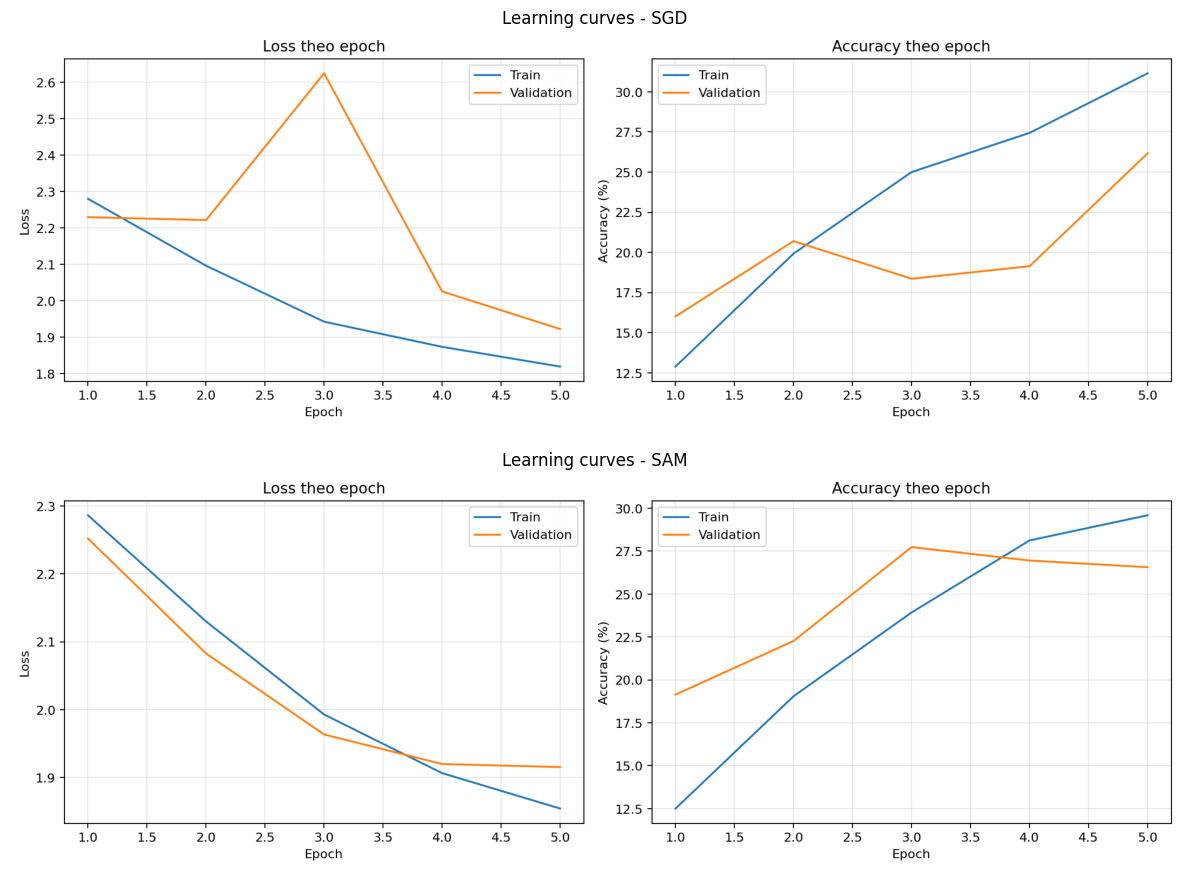

In [12]:
figure, axes = plt.subplots(2, 1, figsize=(12, 9))
for axis, smoke_method in zip(axes, ("sgd", "sam")):
    curve_path = RESULTS_ROOT / f"smoke_{smoke_method}_s{SEED}" / "learning_curves.png"
    axis.imshow(plt.imread(curve_path))
    axis.set_title(f"Learning curves - {smoke_method.upper()}")
    axis.axis("off")
figure.tight_layout()
plt.show()

## 11. Load checkpoint và dự đoán một batch

Cell cuối tạo một model mới, load `best_checkpoint.pt` và dự đoán một batch test. Đây là bước kiểm tra checkpoint có thể tái sử dụng cho demo.

Có thể truyền đường dẫn checkpoint của full run đã chuẩn bị trước thay vì chạy lại 200 epochs trong lúc thuyết trình.

In [13]:
@torch.no_grad()
def load_checkpoint_and_predict(checkpoint_path, loader, device=DEVICE):
    """Load model mới từ checkpoint và trả về một batch dự đoán."""
    checkpoint_path = Path(checkpoint_path)
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
    checkpoint_config = checkpoint["config"]

    reloaded_model = build_model(checkpoint_config["model"]).to(device)
    reloaded_model.load_state_dict(checkpoint["model_state_dict"])
    reloaded_model.eval()

    images, targets = next(iter(loader))
    logits = reloaded_model(images.to(device, non_blocking=True))
    predictions = logits.argmax(dim=1).cpu()

    if logits.shape != (images.size(0), 10):
        raise RuntimeError(f"Logits có shape không hợp lệ: {tuple(logits.shape)}")

    return reloaded_model, images, targets, predictions


def show_predictions(images, targets, predictions, max_images=8):
    """Hiển thị một số ảnh cùng nhãn thật và dự đoán."""
    image_count = min(max_images, len(images))
    figure, axes = plt.subplots(2, 4, figsize=(12, 6))
    axes = axes.ravel()
    mean = torch.tensor(CIFAR10_MEAN).view(3, 1, 1)
    std = torch.tensor(CIFAR10_STD).view(3, 1, 1)

    for index, axis in enumerate(axes):
        if index >= image_count:
            axis.axis("off")
            continue
        image = (images[index].cpu() * std + mean).clamp(0, 1)
        image = image.permute(1, 2, 0).numpy()
        true_name = CIFAR10_CLASSES[int(targets[index])]
        predicted_name = CIFAR10_CLASSES[int(predictions[index])]
        color = "green" if true_name == predicted_name else "red"
        axis.imshow(image)
        axis.set_title(f"Thật: {true_name}\nĐoán: {predicted_name}", color=color)
        axis.axis("off")

    figure.tight_layout()
    plt.show()


# Ví dụ demo trực tiếp checkpoint SAM sau khi smoke pair hoàn tất:
# _, _, _, demo_test_loader, _ = build_dataloaders()
# reloaded_model, images, targets, predictions = load_checkpoint_and_predict(
#     RESULTS_ROOT / f"smoke_sam_s{SEED}" / "best_checkpoint.pt",
#     demo_test_loader,
# )
# show_predictions(images, targets, predictions)

## 12. Checklist trước khi chạy full experiment

- [ ] Google Drive đã mount và artifact nằm trong `MyDrive/CS2229-SAM/results`.
- [ ] Smoke test chạy đủ 5 epochs với cả SGD và SAM.
- [ ] Hai method dùng cùng `SPLIT_SEED`, augmentation và model.
- [ ] SAM dùng lại cùng mini-batch cho hai gradient evaluations.
- [ ] BatchNorm running statistics không cập nhật ở pass thứ hai.
- [ ] Có đủ bảy artifact và `summary.json` đọc được.
- [ ] Checkpoint load lại được và inference trả về 10 logits mỗi ảnh.
- [ ] Đã ước lượng tổng thời gian và peak GPU memory.
- [ ] Cả nhóm đã chốt cùng model trước khi chạy core matrix.
- [ ] `RUN_ID` đúng với run matrix; nếu tồn tại thì đó phải là run chưa hoàn tất có cùng cấu hình.
- [ ] `RESUME_IF_EXISTS=True` và `last_checkpoint.pt` được ghi trên Google Drive sau epoch đầu.
- [ ] Đã lưu một bản notebook cố định hoặc ghi lại Git commit.

Kết quả smoke test chỉ xác nhận pipeline hoạt động. Không dùng accuracy của tập con smoke test để kết luận SAM tốt hơn SGD. Vì smoke test đồng thời dùng model nhỏ hơn và tập con dữ liệu, thời gian và bộ nhớ của nó **không** dùng để ngoại suy trực tiếp cho WRN-28-10 full run. Muốn chốt model hoặc batch size, cần thêm một benchmark ngắn bằng chính cấu hình full run.

`final_train_accuracy` dùng nhãn training sau khi thêm noise và có augmentation. `checkpoint_train_accuracy` cùng `generalization_gap` dùng train split với nhãn sạch, không augmentation, tại best checkpoint.

Notebook hỗ trợ resume ở ranh giới epoch. Khi Colab ngắt phiên, mount lại cùng Google Drive, giữ nguyên toàn bộ cấu hình và `RUN_ID`, rồi chạy lại từ đầu notebook. Pipeline load `last_checkpoint.pt` và tiếp tục từ epoch kế tiếp. Không xóa thư mục run dở; chỉ đổi `RUN_ID` khi chủ động bắt đầu một run mới.